# Kaggle Competition
Due Nov 11

Team 27: Rachel Liu, Henry Lam, Yang Xiao

The PR should include
* implementation,
* experimental code,
* README,
* dependencies, and
* instructions for generating your Kaggle predictions.

Your PR should preserve meaningful development history, including experiments, debugging, and changes to your approach

## Option 1: Neural Net
0. preprocess
1. pick a **model class**, 
2. an **estimation principle**
3. turn it into a **loss**,
4. **optimize** it, 
5. then **predict and evaluate** 

In [2]:
%matplotlib inline
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import torch
from torch import nn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from scipy.sparse import hstack

SEED = 27   # team number, so every run uses the same split and weight initialization
np.random.seed(SEED)
torch.manual_seed(SEED)

### Step 0: Preprocess Data
Make the raw data (attributes) usable via featurization, PCA.

#### (a) Load the data

In [3]:
train_df = pd.read_csv("data/train.csv")   # id, text, label (1 = AI, 0 = human)
test_df = pd.read_csv("data/test.csv")     # id, text (no labels, this is what we submit predictions for)

print("train.csv shape:", train_df.shape)
print("test.csv  shape:", test_df.shape)
print("fraction labeled AI:", train_df["label"].mean())   # 0.5 means the classes are balanced
train_df.head()

train.csv shape: (10000, 3)
test.csv  shape: (3000, 2)
fraction labeled AI: 0.5


,id,text,label
0,1,Cipriani S.A. is an Italian hotel and leisure ...,0
1,2,My Grandpa passed away 3 years ago from cancer...,0
2,3,"""Petit Beurre -- Butter Cookies\n\n1 cup (2 st...",1
3,4,"In an unprecedented move, a dedicated gamer ha...",1
4,5,Chile's copper industry has registered record ...,0


#### (b) Split the training data
1. Fit on the training set, 
2. use the held-out development set to compare models,
3. pick hyperparameters, and
4. decide when to stop training.

Since the test set has no labels the held-out dev set will be used to compare models.

In [4]:
train_set, dev_set = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df["label"]
)

y_train = train_set["label"].values
y_dev = dev_set["label"].values

print("training set size:   ", len(train_set), f"({y_train.mean()*100}% AI)")
print("development set size:", len(dev_set), f"({y_dev.mean()*100}% AI)")

training set size:    8000 (50.0% AI)
development set size: 2000 (50.0% AI)


#### (c) Clean the text
We keep punctuation and capitalization because *how* the text is written likely plays a large part in whether the text is human versus AI. I'm thinking m-dashes and "you're absolutely right" for AI, and typos for humans.  

In [5]:
def clean_text(text):
    # Collapse runs of spaces/newlines into a single space
    return re.sub(r"\s+", " ", text).strip()

train_text = train_set["text"].map(clean_text)
dev_text = dev_set["text"].map(clean_text)

print(train_text.iloc[0][:400])

An $N$-level quantum system is coupled to a bosonic heat reservoir at positive temperature. We analyze the system-reservoir dynamics in the following regime: The strength $\lambda$ of the system-reservoir coupling is fixed and small, but larger than the spacing $\sigma$ of system energy levels. For vanishing $\sigma$ there is a manifold of invariant system-reservoir states and for $\sigma>0$ the o


#### (d) Featurize: TF-IDF on words and characters
Instead of the 0/1 binary that we've use in the past for bag-of-words, we're now replacing that with weights through TF-IDF. 
Based on research, it seems like best practice to include both a 
* word vectorizer to look at **what** is said (vocabulary, common phrases), and also a 
* character vectorizer to look at **how** it is said (punctuation habits, spelling, word endings).

As always, vectorizers are fit on the training set only, then applied to dev with the same vocabulary.

In [6]:
word_vectorizer = TfidfVectorizer(
    lowercase=True, ngram_range=(1, 2), min_df=3, max_features=20000, sublinear_tf=True
)
char_vectorizer = TfidfVectorizer(
    lowercase=False, analyzer="char_wb", ngram_range=(3, 5), min_df=5, max_features=30000, sublinear_tf=True
)

# hstack adds the two sparse matrices side by side: d = (#word features) + (#char features)
X_train = hstack([word_vectorizer.fit_transform(train_text),
                  char_vectorizer.fit_transform(train_text)]).tocsr()
X_dev = hstack([word_vectorizer.transform(dev_text),
                char_vectorizer.transform(dev_text)]).tocsr()

print("train matrix:", X_train.shape, "   dev matrix:", X_dev.shape)

train matrix: (8000, 50000)    dev matrix: (2000, 50000)


#### (e) Wrap the data for PyTorch
The matrices are sparse which means they are mostly zeros. We only need to turn one **minibatch** of rows into a dense tensor at a time because converting the entire one would take a lot of memory. 

In [7]:
class SparseTextDataset(torch.utils.data.Dataset):
    def __init__(self, X, y=None):
        self.X = X   # scipy sparse matrix, shape (n, d)
        self.y = y   # numpy array of 0/1 labels, or None for the test set

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        return i   # just hand back row indices; collate() builds the batch

    def collate(self, idx):
        # Slice the rows for this batch and convert only those to a dense float tensor.
        xb = torch.tensor(self.X[idx].toarray(), dtype=torch.float32)
        if self.y is None:
            return xb
        yb = torch.tensor(self.y[idx], dtype=torch.float32)
        return xb, yb

def make_loader(X, y=None, batch_size=64, shuffle=False):
    ds = SparseTextDataset(X, y)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=ds.collate)

train_loader = make_loader(X_train, y_train, shuffle=True)   # reshuffle every epoch for SGD
dev_loader = make_loader(X_dev, y_dev)

xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape)

one batch: torch.Size([64, 50000]) torch.Size([64])


### Step 1: Parametrize
The model class is a **multilayer perceptron** (MLP) where each layer computes the **activation** of the weighted inputs plus bias, feeding forward per layer. 

In [8]:
# this defines a simple feedforward neural network with dropout and a choice of activation function.
class MLP(nn.Module):
    def __init__(self, sizes, activation="relu", dropout=0.5):
        super().__init__()
        self.sizes = sizes
        # one Linear layer per pair of consecutive sizes, W^[k] has shape (sizes[k], sizes[k-1])
        self.layers = nn.ModuleList([nn.Linear(m, n) for m, n in zip(sizes[:-1], sizes[1:])])
        self.g = nn.ReLU() if activation == "relu" else nn.Sigmoid()
        self.dropout = nn.Dropout(dropout)   # only active in model.train() mode

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = self.dropout(self.g(layer(x)))   # A^[k] = g(W^[k] A^[k-1] + b^[k])
        # last layer: no activation, one logit per example; squeeze(-1) turns (batch, 1) into (batch,)
        return self.layers[-1](x).squeeze(-1)

SIZES = [X_train.shape[1], 256, 64, 1]
model = MLP(SIZES)
print(model)
print("number of parameters:", sum(p.numel() for p in model.parameters()))

MLP(
  (layers): ModuleList(
    (0): Linear(in_features=50000, out_features=256, bias=True)
    (1): Linear(in_features=256, out_features=64, bias=True)
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (g): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
)
number of parameters: 12816769


### Step 2: Choose Estimation Principle
We will use **Maximum likelihood / logistic regression**. We model each label as a
Bernoulli RV whose probability comes from the network and choose theta to make observed training labels as likely as possible which is the process of .

We also add **L2 penalty** to reduce overfitting

### Step 3: Define a Loss/Objective Function
Maximizing the log-likelihood = minimizing its negative, which is the **binary cross-entropy** loss. 
* Pass raw model logits and 0/1 labels; this loss applies sigmoid internally and
* computes the mean binary cross-entropy for the batch.

In [9]:
loss_fn = nn.BCEWithLogitsLoss()

### Step 4: Optimize
#### (a) Backpropagation via PyTorch
PyTorch's `loss.backward()` derives the gradient with cross entropy and sigmoid output. It flows backwards by applying the weighted deltas to the layers below it. 
We also decided to use Adam which converges faster that SGD. 

In [10]:
# this checks how the model performs on a dataset (the dev set) and returns the average loss and predicted probabilities
# does not update the model  
def evaluate(model, loader):
    # Average loss and predicted probabilities over a whole dataset, without updating weights.
    model.eval()                       # turns dropout off
    losses, probs = [], []
    with torch.no_grad():              # no need to track gradients here
        for xb, yb in loader:
            logits = model(xb)
            losses.append(loss_fn(logits, yb).item() * len(yb))
            probs.append(torch.sigmoid(logits))
    return sum(losses) / len(loader.dataset), torch.cat(probs).numpy()

# this summarized the gradients for each layer and plots how strongly each layer should change to reduce loss
# norm gives one size for that layer's gradients
def layer_grad_norms(model):
    # ||(dW^[k], db^[k])|| for every layer k, like grad_layer1..3 in the lecture
    return [float(torch.sqrt(l.weight.grad.pow(2).sum() + l.bias.grad.pow(2).sum())) for l in model.layers]

# this trains the model for multiple epoch and calculates the loss w/ autograd
# also uses Adam to update the weights and then
# stores the weights so that the one with the lowest dev loss is used at the end
def train(model, train_loader, dev_loader=None, epochs=15, lr=1e-3, weight_decay=1e-5, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []                       # one row per epoch, like the lecture's `rows`
    best_dev_loss, best_state = float("inf"), None
    L = len(model.layers)

    for epoch in range(1, epochs + 1):
        model.train()                  # turns dropout on
        total, grad_sum = 0.0, np.zeros(L)
        for xb, yb in train_loader:
            optimizer.zero_grad()      # clear gradients from the previous batch
            loss = loss_fn(model(xb), yb)   # forward pass + loss
            loss.backward()            # backpropagation: compute dJ/dtheta
            grad_sum += layer_grad_norms(model)
            optimizer.step()           # theta <- theta - lr * (adjusted) gradient
            total += loss.item() * len(yb)

        row = {"epoch": epoch, "train_loss": total / len(train_loader.dataset)}
        row.update({f"grad_layer{k+1}": g / len(train_loader) for k, g in enumerate(grad_sum)})
        row["weight_norm"] = float(torch.sqrt(sum(l.weight.detach().pow(2).sum() for l in model.layers)))

        msg = f"epoch {epoch:2d}   train loss {row['train_loss']:.4f}"
        if dev_loader is not None:
            dev_loss, p = evaluate(model, dev_loader)
            row["dev_loss"] = dev_loss
            row["dev_accuracy"] = accuracy_score(dev_loader.dataset.y, p >= 0.5)
            msg += f"   dev loss {dev_loss:.4f}   dev acc {row['dev_accuracy']:.4f}"
            # Early stopping: remember the best weights seen so far
            if dev_loss < best_dev_loss:
                best_dev_loss = dev_loss
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        history.append(row)
        if verbose:
            print(msg)

    if best_state is not None:
        model.load_state_dict(best_state)   # roll back to the best epoch
    return pd.DataFrame(history).set_index("epoch")

In [11]:
# here we tune our hyperparameters on the dev set
SIZES = [X_train.shape[1], 256, 64, 1]
ACTIVATION = "relu"
DROPOUT = 0.5
LR = 1e-4    
WEIGHT_DECAY = 1e-5
EPOCHS = 12

torch.manual_seed(SEED)
model = MLP(SIZES, ACTIVATION, DROPOUT)
history = train(model, train_loader, dev_loader, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)

best_epoch = int(history["dev_loss"].idxmin())
print("best epoch:", best_epoch)
history.round(4)

epoch  1   train loss 0.6822   dev loss 0.6569   dev acc 0.7165
epoch  2   train loss 0.5722   dev loss 0.4863   dev acc 0.8390
epoch  3   train loss 0.3738   dev loss 0.3601   dev acc 0.8620
epoch  4   train loss 0.2518   dev loss 0.3116   dev acc 0.8645
epoch  5   train loss 0.1809   dev loss 0.2928   dev acc 0.8700
epoch  6   train loss 0.1301   dev loss 0.2891   dev acc 0.8690
epoch  7   train loss 0.0986   dev loss 0.2892   dev acc 0.8710
epoch  8   train loss 0.0720   dev loss 0.2950   dev acc 0.8720
epoch  9   train loss 0.0546   dev loss 0.3039   dev acc 0.8695
epoch 10   train loss 0.0397   dev loss 0.3147   dev acc 0.8715
epoch 11   train loss 0.0306   dev loss 0.3328   dev acc 0.8695
epoch 12   train loss 0.0229   dev loss 0.3401   dev acc 0.8725
best epoch: 6


,train_loss,grad_layer1,grad_layer2,grad_layer3,weight_norm,dev_loss,dev_accuracy
epoch,,,,,,,
1,0.6822,0.0619,0.0482,0.0718,10.0495,0.6569,0.7165
2,0.5722,0.1480,0.1006,0.1883,15.0019,0.4863,0.8390
3,0.3738,0.2316,0.1264,0.2506,19.4924,0.3601,0.8620
4,0.2518,0.2766,0.1253,0.2179,22.4051,0.3116,0.8645
5,0.1809,0.2845,0.1126,0.1836,24.4713,0.2928,0.8700
6,0.1301,0.2691,0.0981,0.1528,26.1034,0.2891,0.8690
7,0.0986,0.2557,0.0857,0.1302,27.4357,0.2892,0.8710
8,0.0720,0.2253,0.0711,0.1104,28.5826,0.2950,0.8720
9,0.0546,0.1975,0.0598,0.0923,29.5368,0.3039,0.8695


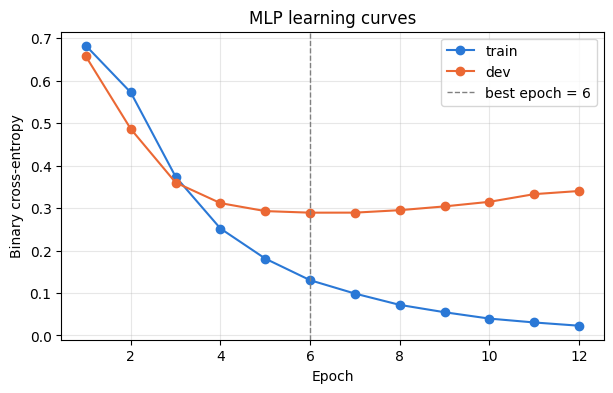

In [12]:
# here we plot the learning curves
# if we see that dev loss is going up while train loss is going down, that means we are overfitting
plt.figure(figsize=(7, 4))
plt.plot(history.index, history["train_loss"], marker="o", color="#2a78d6", label="train")
plt.plot(history.index, history["dev_loss"], marker="o", color="#eb6834", label="dev")
plt.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"best epoch = {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("MLP learning curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

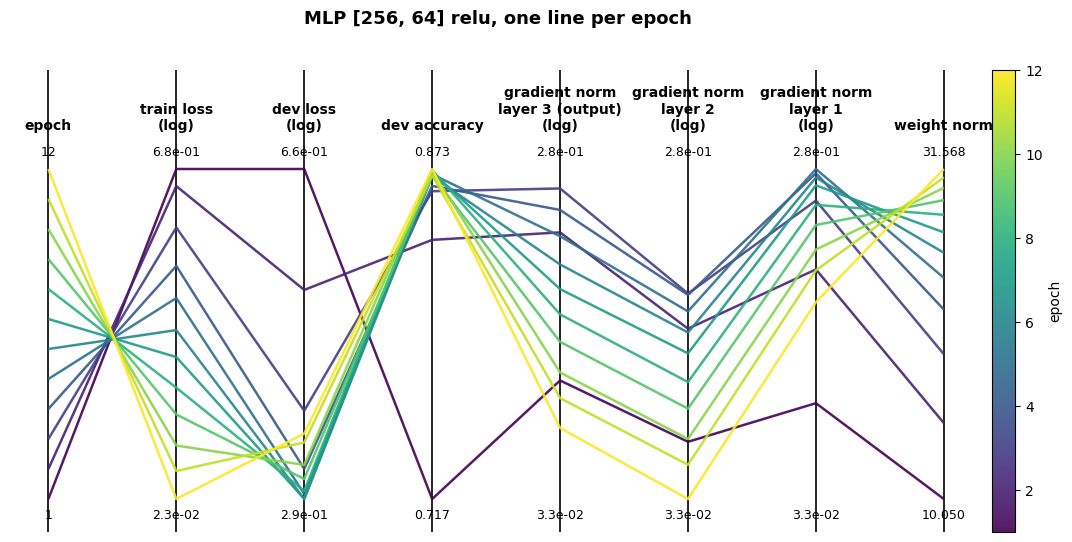

In [13]:
# parallel coordinates plot to see how the gradients change over time for each layer
# we did something similar in lecture 13, felt it was helpful to visualize
def parallel_coordinates(history, title):
    rows = history.reset_index()
    grad_cols = [c for c in rows.columns if c.startswith("grad_layer")]
    axes = ([("epoch", "epoch", False), ("train_loss", "train loss", True), ("dev_loss", "dev loss", True),
             ("dev_accuracy", "dev accuracy", False)]
            + [(c, f"gradient norm\nlayer {c[-1]}" + (" (output)" if c == grad_cols[-1] else ""), True)
               for c in reversed(grad_cols)]
            + [("weight_norm", "weight norm", False)])
    M = rows[[k for k, _, _ in axes]].to_numpy(dtype=float)
    V = np.column_stack([np.log10(np.maximum(M[:, j], 1e-12)) if lg else M[:, j] for j, (_, _, lg) in enumerate(axes)])
    GR = [j for j, (k, _, _) in enumerate(axes) if k.startswith("grad")]
    glo, ghi = V[:, GR].min(), V[:, GR].max()               # one scale for all gradient axes
    Z = np.zeros_like(V)
    for j in range(len(axes)):
        lo, hi = (glo, ghi) if j in GR else (V[:, j].min(), V[:, j].max())
        Z[:, j] = (V[:, j] - lo) / (hi - lo + 1e-12)

    fig, ax = plt.subplots(figsize=(13, 6))
    xs = np.arange(len(axes))
    lc = LineCollection([np.column_stack([xs, z]) for z in Z], array=M[:, 0], cmap="viridis",
                        linewidths=1.8, alpha=0.9)
    ax.add_collection(lc)
    for j, (key, label, lg) in enumerate(axes):
        ax.axvline(j, color="black", lw=1.2, zorder=0)
        lo, hi = (10 ** glo, 10 ** ghi) if j in GR else (M[:, j].min(), M[:, j].max())
        fmt = (lambda v: f"{v:.0f}") if key == "epoch" else (lambda v: f"{v:.1e}") if lg else (lambda v: f"{v:.3f}")
        ax.text(j, 1.03, fmt(hi), ha="center", va="bottom", fontsize=9)
        ax.text(j, -0.03, fmt(lo), ha="center", va="top", fontsize=9)
        ax.text(j, 1.11, label + ("\n(log)" if lg else ""), ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_xlim(-0.3, len(axes) - 0.7)
    ax.set_ylim(-0.1, 1.3)
    ax.axis("off")
    fig.colorbar(lc, ax=ax, fraction=0.025, pad=0.01).set_label("epoch")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.show()

parallel_coordinates(history, f"MLP {SIZES[1:-1]} {ACTIVATION}, one line per epoch")

### Step 5: Predict and Evaluate
#### (a) Evaluate on the dev set
The submission asks for a probability per text, so in addition to 
* accuracy and 
* F1 we also look at 
* log loss and
* ROC AUC. 
Unlike accuracy and F1, log loss and ROC AUC score the probabilities themselves rather than just the 0/1 binary decision.

In [14]:
def report(name, y_true, p):
    # p = predicted P(AI); threshold at 0.5 for the hard 0/1 metrics
    y_pred = (p >= 0.5).astype(int)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "log loss": log_loss(y_true, p),
        "ROC AUC": roc_auc_score(y_true, p),
    }

_, p_train = evaluate(model, make_loader(X_train, y_train))
_, p_dev = evaluate(model, dev_loader)

results = pd.DataFrame([
    report("MLP (train)", y_train, p_train),
    report("MLP (dev)", y_dev, p_dev),
]).set_index("model")
results.round(4)

,accuracy,F1,log loss,ROC AUC
model,,,,
MLP (train),0.9875,0.9874,0.0867,0.9986
MLP (dev),0.8690,0.8633,0.2891,0.9469


In [15]:
# Look at the dev texts the model got most confidently wrong, to get ideas for better features.
dev_view = dev_set.assign(p_ai=p_dev)
wrong = dev_view[(dev_view["p_ai"] >= 0.5) != (dev_view["label"] == 1)]
wrong = wrong.reindex((wrong["p_ai"] - 0.5).abs().sort_values(ascending=False).index)
for _, row in wrong.head(10).iterrows():
    print(f"label={row['label']}   P(AI)={row['p_ai']:.3f}\n{row['text'][:300]}...\n")

label=1   P(AI)=0.005
Meatloaf: Incredible and Edible!

(serves 8 to 10)

1 pkg panko bread crumbs

1 tablespoon finely minced onion

1 tablespoon finely minced garlic

1 tablespoon sugar

2 tablespoons melted butter, preferably butter from a can

salt and pepper

1 loaf sourdough loaf or ciabatta bread or a combination ...

label=1   P(AI)=0.021
Tonight, I hung myself. Not just metaphorically, but literally. I found the closest thing to a noose that was around the house and secured it to the ceiling of my bedroom closet. I had been feeling extremely depressed, hopeless, and lost for a while now, and tonight was the breaking point. I sat on ...

label=1   P(AI)=0.025
Monday night's marquee match in the SAP Open in San Jose turned out to be anything but as qualifier Jurgen Melzer stunned home favourite Andre Agassi 6-3 6-4. 

Much was expected of Agassi in his return to the first ATP event he ever played as a 16-year-old in 1986.

But the eight-time Grand Slam ch...

label=1   P(AI)=0.0

#### (b) Retrain on all labeled data and predict the test set
Once hyperparameters are chosen, refit the vectorizers and the network on train + dev for the number of epochs that was best on dev (6).
There's no dev set left for early stopping, so `best_epoch` stands in for it.

In [16]:
full_text = train_df["text"].map(clean_text)
y_full = train_df["label"].values
test_text = test_df["text"].map(clean_text)

# Refit both vectorizers on all labeled text, then transform test with the same vocabulary.
X_full = hstack([word_vectorizer.fit_transform(full_text),
                 char_vectorizer.fit_transform(full_text)]).tocsr()
X_test = hstack([word_vectorizer.transform(test_text),
                 char_vectorizer.transform(test_text)]).tocsr()
print("full matrix:", X_full.shape, "   test matrix:", X_test.shape)

torch.manual_seed(SEED)
final_model = MLP([X_full.shape[1]] + SIZES[1:], ACTIVATION, DROPOUT)
train(final_model, make_loader(X_full, y_full, shuffle=True), epochs=best_epoch, lr=LR, weight_decay=WEIGHT_DECAY);

full matrix: (10000, 50000)    test matrix: (3000, 50000)
epoch  1   train loss 0.6754
epoch  2   train loss 0.5158
epoch  3   train loss 0.3161
epoch  4   train loss 0.2190
epoch  5   train loss 0.1576
epoch  6   train loss 0.1171


In [17]:
# Predict P(AI) for each test text. The test loader has no labels, so we don't use evaluate().
final_model.eval()
with torch.no_grad():
    p_test = torch.cat([torch.sigmoid(final_model(xb))
                        for xb in make_loader(X_test)]).numpy()

# Same format as sample_submission.csv: id, label (probability of AI)
submission = pd.DataFrame({"id": test_df["id"], "label": p_test})
submission.to_csv("submission_nn1.csv", index=False)
print(submission.shape)
submission.head()

(3000, 2)


,id,label
0,13001,0.992773
1,13002,0.135954
2,13003,0.708865
3,13004,0.021657
4,13005,0.950794
